# 27 基于 ARIMA 算法的餐厅营业额预测分析

> **模块**：时间序列 ｜ **数据**：`arima_data.xlsx` ｜ **依赖**：pandas、matplotlib、statsmodels

## 1. 问题背景

本实验利用某餐厅菜品销量的时间序列数据，通过ARIMA模型对销量进行时间序列预测。

本实验使用的数据是某家餐厅的营业数据，包含日期和销量两列。日期范围为2015年1月1日至2015年2月6日。

本实验首先对原始时间序列的平稳性进行检验，检验方法包括自相关图和ADF单位根检验等；判断原序列是否为非平稳序列后，需要对数据进行差分；然后再判断差分后的数据是否为平稳序列；如果差分后的数据是平稳序列，则确定ARIMA模型的参数取值，最后训练模型并进行预测。


## 2. 学习目标

- 学习检测时间序列平稳性的方法
- 学习基于 ARIMA 模型的时间序列预测方法


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 数据准备

#### 4.1.1 导入常用数据分析工具包，并导入数据

```bash
pip install numpy==1.26.0 pandas==1.3.3 -i https://pypi.tuna.tsinghua.edu.cn/simple
```


In [1]:
import pandas as pd, warnings
warnings.filterwarnings('ignore')
discfile = '../data/arima_data.xlsx'
data = pd.read_excel(discfile,index_col = 0)
print(data.head())
print('\n Data Types:')
print(data.dtypes)

              销量
日期              
2015-01-01  3023
2015-01-02  3039
2015-01-03  3056
2015-01-04  3138
2015-01-05  3188

 Data Types:
销量    int64
dtype: object


#### 4.1.2 数据可视化

<Axes: xlabel='日期'>

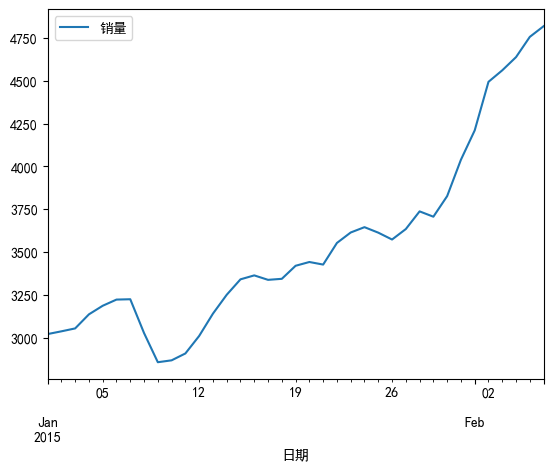

In [2]:
#导入matplotlib可视化工具包
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei'] 
plt.rcParams['axes.unicode_minus'] = False 
data.plot()

从该运行结果可以看出，该数据序列具有明显的单调递增趋势，可以初步判断为非平稳序列。

### 4.2 数据预处理

#### 4.2.1 自相关图

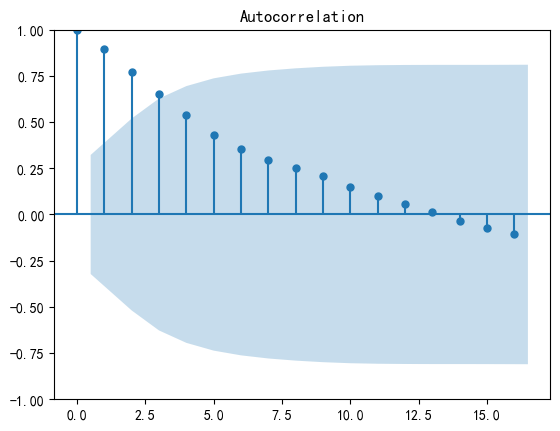

In [3]:
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(data).show()

从运行结果可以看出，自相关系数衰减的波动过程比较缓慢或非常连续，也就是acf图拖尾，原始数据具有很强的长期自相关性。

#### 4.2.2 平稳性检测

In [4]:
# 导入ADF单位根检验
from statsmodels.tsa.stattools import adfuller as ADF
# 打印原始序列ADF检验结果
print(u'原始序列的ADF检验结果为：',ADF(data[u'销量']))

原始序列的ADF检验结果为： (1.813771015094527, 0.9983759421514264, 10, 26, {'1%': -3.7112123008648155, '5%': -2.981246804733728, '10%': -2.6300945562130176}, 299.46989866024177)


从ADF结果可以看出单位根检验统计量p值为0.9983759421514264，显著大于0.05，确定该序列为非平稳序列。

#### 4.2.3 对原始序列进行一阶差分

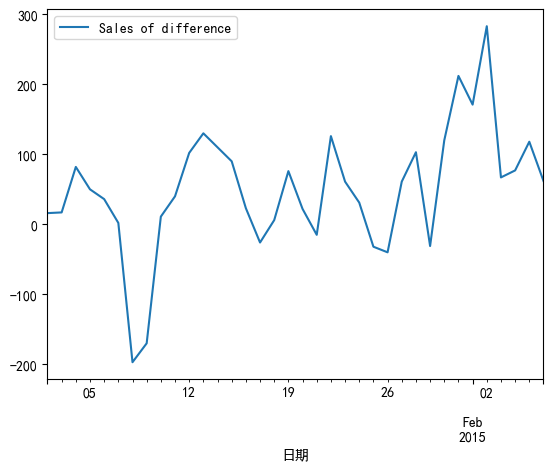

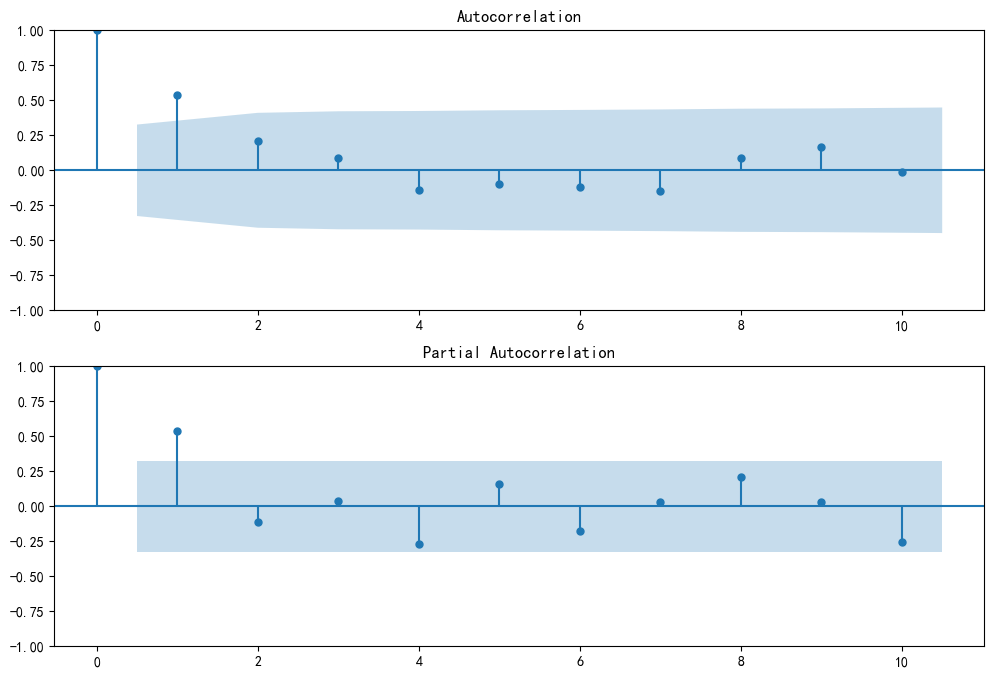

差分序列的ADF检验结果为： (-3.156056236672353, 0.02267343544004886, 0, 35, {'1%': -3.6327426647230316, '5%': -2.9485102040816327, '10%': -2.6130173469387756}, 287.5909090780334)


In [5]:
#对数据进行一阶差分操作
D_data = data.diff().dropna()
#销量差分
D_data.columns= [u'Sales of difference']
# 差分后的时序图
D_data.plot() 
plt.show()

import statsmodels.api as sm
fig = plt.figure(figsize = (12,8))
ax1 = fig.add_subplot(211)
# 一阶差分后的自相关图
fig1 = sm.graphics.tsa.plot_acf(D_data[u'Sales of difference'],lags=10,ax=ax1)
ax2 = fig.add_subplot(212)
# 一阶差分后的偏相关图
fig2 = sm.graphics.tsa.plot_pacf(D_data[u'Sales of difference'],lags=10,ax=ax2)
plt.show()

# 一阶差分后的ADF检验
print(u'差分序列的ADF检验结果为：',ADF(D_data[u'Sales of difference']))

从运行结果可以看出，一阶差分之后序列的时序图在均值附近比较平稳的波动；自相关图有很强的短期相关性；偏自相关图显示出拖尾性；单位根检验的p值为0.0226734小于0，05；因此可以判断一阶差分后的序列是平稳序列。

### 4.3 ARIMA 模型预测

#### 4.3.1 训练 ARIMA 模型

使用ARIMA（p,d,q）模型，其中一阶差分d=1。根据一阶差分后的自相关图1阶截尾，偏相关图拖尾，可选定p=0，q=1.

In [6]:
from statsmodels.tsa.arima.model import ARIMA  # 使用新版本的导入方式
p = 0
d = 1
q = 1
model = ARIMA(data, order=(p, d, q)).fit()
print('模型报告为：\n', model.summary())

模型报告为：
                                SARIMAX Results                                
Dep. Variable:                     销量   No. Observations:                   37
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -208.592
Date:                Sat, 28 Nov 2026   AIC                            421.183
Time:                        17:19:04   BIC                            424.351
Sample:                    01-01-2015   HQIC                           422.289
                         - 02-06-2015                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.7374      0.099      7.447      0.000       0.543       0.931
sigma2      6189.4544   1354.676      4.569      0.000    3534.339    8844.570
Ljung-Box (L1) (Q):                   0.11  

c:\Users\yohoten\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\yohoten\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\yohoten\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


#### 4.3.2 预测未来 5 天的销售数据

In [7]:
# 预测未来5天的销售数据
predict = model.forecast(5)
print('预测结果、标注误差、置信区间如下：\n',predict)

预测结果、标注误差、置信区间如下：
 2015-02-07    4853.378533
2015-02-08    4853.378533
2015-02-09    4853.378533
2015-02-10    4853.378533
2015-02-11    4853.378533
Freq: D, Name: predicted_mean, dtype: float64


<Axes: >

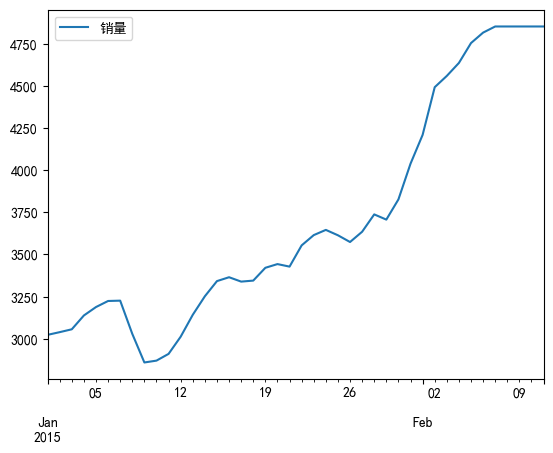

In [8]:
index=pd.date_range(start='20150207',periods=5).tolist()
predict_data = pd.DataFrame({'销量':predict[0]},index=index)
ndata = pd.concat([data,predict_data])
ndata.plot()

利用模型向前预测的时期越长，预测误差将会越大，这是时间预测的典型特点。


## 5. 小结

本实验通过建立ARIMA时间序列预测模型实现了某餐厅销售数据的预测。通过本实验需要重点掌握时间序列预测的原理以及ARIMA模型的实现方法，展现时间序列数据预测的应用。
